# PS3: RNN (SimpleRNN) for character-level text generation

## 1. Setup and GPU / VRAM check

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from tensorflow import keras
from tensorflow.keras import layers

EPOCHS = 15
SEQ_LEN = 40

In [2]:
path = keras.utils.get_file(
    "shakespeare.txt",
    "https://storage.googleapis.com/download.tensorflow.org/data/shakespeare.txt")
text = open(path, encoding="utf-8").read().lower()[:200000]
chars = sorted(set(text))
char_to_id = {c: i for i, c in enumerate(chars)}
print("Characters:", len(text), "Vocabulary:", len(chars))
print(text[:300])

1115394/1115394 ━━━━━━━━━━━━━━━━━━━━ 1s 1us/step
Characters: 200000 Vocabulary: 37
first citizen:
before we proceed any further, hear me speak.

all:
speak, speak.

first citizen:
you are all resolved rather to die than to famish?

all:
resolved. resolved.

first citizen:
first, you know caius marcius is chief enemy to the people.

all:
we know't, we know't.

first citizen:
let us


In [3]:
encoded = np.array([char_to_id[c] for c in text])
starts = range(0, len(encoded) - SEQ_LEN, 3)
X = np.array([encoded[i:i + SEQ_LEN] for i in starts])
y = np.array([encoded[i + SEQ_LEN] for i in starts])
print("X:", X.shape, "y:", y.shape)

X: (66654, 40) y: (66654,)


In [4]:
model = keras.Sequential([
    layers.Input((None,)),
    layers.Embedding(len(chars), 64),
    layers.SimpleRNN(256),
    layers.Dense(len(chars), activation="softmax"),
])
model.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ embedding (Embedding)                │ (None, None, 64)            │           2,368 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ simple_rnn (SimpleRNN)               │ (None, 256)                 │          82,176 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 37)                  │           9,509 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 94,053 (367.39 KB)

 Trainable params: 94,053 (367.39 KB)

 Non-trainable params: 0 (0.00 B)

In [5]:
history = model.fit(X, y, batch_size=128, epochs=EPOCHS, validation_split=0.1, verbose=2)

Epoch 1/15
469/469 - 18s - 39ms/step - accuracy: 0.2810 - loss: 2.5421 - val_accuracy: 0.3327 - val_loss: 2.3042
Epoch 2/15
469/469 - 16s - 34ms/step - accuracy: 0.3682 - loss: 2.1628 - val_accuracy: 0.3573 - val_loss: 2.1840
Epoch 3/15
469/469 - 16s - 34ms/step - accuracy: 0.4091 - loss: 2.0063 - val_accuracy: 0.3893 - val_loss: 2.0810
Epoch 4/15
469/469 - 16s - 34ms/step - accuracy: 0.4418 - loss: 1.8908 - val_accuracy: 0.4022 - val_loss: 2.0386
Epoch 5/15
469/469 - 16s - 35ms/step - accuracy: 0.4628 - loss: 1.8031 - val_accuracy: 0.4133 - val_loss: 1.9790
Epoch 6/15
469/469 - 16s - 35ms/step - accuracy: 0.4839 - loss: 1.7263 - val_accuracy: 0.4298 - val_loss: 1.9449
Epoch 7/15
469/469 - 17s - 36ms/step - accuracy: 0.4966 - loss: 1.6676 - val_accuracy: 0.4271 - val_loss: 1.9279
Epoch 8/15
469/469 - 17s - 37ms/step - accuracy: 0.5121 - loss: 1.6169 - val_accuracy: 0.4451 - val_loss: 1.9014
Epoch 9/15
469/469 - 17s - 36ms/step - accuracy: 0.5211 - loss: 1.5749 - val_accuracy: 0.4449 - 

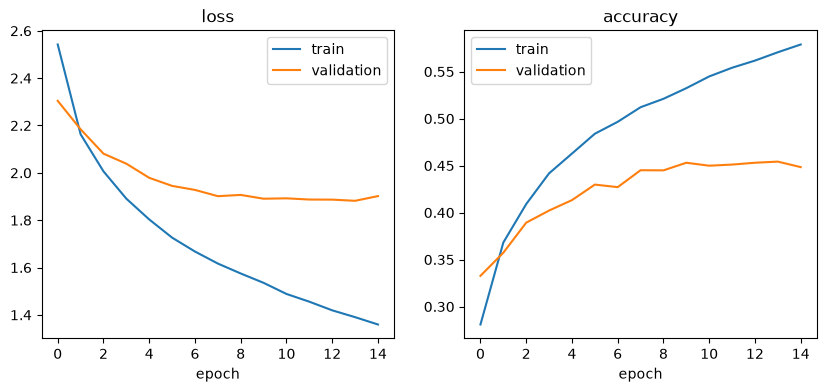

Final validation accuracy: 0.4484
Validation perplexity: 6.70


In [6]:
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
for i, metric in enumerate(["loss", "accuracy"]):
    ax[i].plot(history.history[metric], label="train")
    ax[i].plot(history.history["val_" + metric], label="validation")
    ax[i].set_title(metric)
    ax[i].set_xlabel("epoch")
    ax[i].legend()
plt.show()
print(f"Final validation accuracy: {history.history['val_accuracy'][-1]:.4f}")
print(f"Validation perplexity: {np.exp(history.history['val_loss'][-1]):.2f}")

In [ ]:
def generate(seed, length=300, temperature=0.5):
    out = seed.lower()
    for _ in range(length):
        x = np.array([[char_to_id[c] for c in out[-SEQ_LEN:]]])
        probs = model(x, training=False).numpy()[0].astype("float64")
        probs = np.exp(np.log(probs + 1e-9) / temperature)
        probs /= probs.sum()
        out += chars[np.random.choice(len(chars), p=probs)]
    return out


seed = text[1000:1000 + SEQ_LEN]
for t in [0.2, 0.5, 1.0]:
    print(f"--- temperature {t} ---")
    print(generate(seed, temperature=t))
    print()

--- temperature 0.2 ---
second citizen:
would you proceed especins
that we dean you the common to the corsest to see him sour good to the corioni have been from me to the common to the common to speak of hear not see the gods be not to be so me tourd to his grans to be so for the corioling of the people, that we will so from the common to see your good for the c

--- temperature 0.5 ---
second citizen:
would you proceed especing the people, well, so never his general in the people with him to be sot be so the common to seef on the wors
if the not;
sir some to the people i' the bell man speak of hear
not in common privicour nay, getting to see have food for to have been fir in the gods be granged not to be so be so be; fo

--- temperature 1.0 ---
